<a href="https://colab.research.google.com/github/Serhatozdemir34/biyometrik-sistemler-parmak-izi/blob/main/parmak_izi_siniflandirma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#google drive bağlandık
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#çalışma klasorumuzun içerisine girdik
%cd "/content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma"

/content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma


In [ ]:
# bulundugumuz lokasyonu kontrol ettik
%pwd

'/content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma'

In [ ]:
#veri setimizi zipten çıkartık
!unzip "/content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma/Fingerprint pattern classifier.v1i.folder.zip"  -d parmakizi_dataset

Archive:  /content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma/Fingerprint pattern classifier.v1i.folder.zip
replace parmakizi_dataset/README.dataset.txt? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: parmakizi_dataset/README.dataset.txt  
  inflating: parmakizi_dataset/README.roboflow.txt  
 extracting: parmakizi_dataset/test/concentric_whorl/class2_Whorl_0040_png.rf.81258abea7d71787735de4633bff359d.jpg  
 extracting: parmakizi_dataset/test/concentric_whorl/class2_Whorl_0047_png.rf.5e76b2c7b03fdab8f2d2403e5e6f9965.jpg  
 extracting: parmakizi_dataset/test/concentric_whorl/class2_Whorl_0142_png.rf.db6a2c270b2604be2b631dab0e946b1f.jpg  
 extracting: parmakizi_dataset/test/concentric_whorl/class2_Whorl_0152_png.rf.ab35bc9eec8f08aaaf615681f5295a6e.jpg  
 extracting: parmakizi_dataset/test/concentric_whorl/class2_Whorl_0153_png.rf.84062e49bc471d62797e7581281ca31c.jpg  
 extracting: parmakizi_dataset/test/concentric_whorl/class2_Whorl_0160_png.rf.2f482244fd52bc7d

In [ ]:
# Veri setini geçici çalışma alanına çıkartıyoruz
!unzip "/content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma/Fingerprint pattern classifier.v1i.folder.zip" -d /content/parmakizi_dataset

Archive:  /content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma/Fingerprint pattern classifier.v1i.folder.zip
  inflating: /content/parmakizi_dataset/README.dataset.txt  
  inflating: /content/parmakizi_dataset/README.roboflow.txt  
   creating: /content/parmakizi_dataset/test/
   creating: /content/parmakizi_dataset/test/concentric_whorl/
 extracting: /content/parmakizi_dataset/test/concentric_whorl/class2_Whorl_0040_png.rf.81258abea7d71787735de4633bff359d.jpg  
 extracting: /content/parmakizi_dataset/test/concentric_whorl/class2_Whorl_0047_png.rf.5e76b2c7b03fdab8f2d2403e5e6f9965.jpg  
 extracting: /content/parmakizi_dataset/test/concentric_whorl/class2_Whorl_0142_png.rf.db6a2c270b2604be2b631dab0e946b1f.jpg  
 extracting: /content/parmakizi_dataset/test/concentric_whorl/class2_Whorl_0152_png.rf.ab35bc9eec8f08aaaf615681f5295a6e.jpg  
 extracting: /content/parmakizi_dataset/test/concentric_whorl/class2_Whorl_0153_png.rf.84062e49bc471d62797e7581281ca31c.jpg  
 extract

# Gerekli Kütüphaneleri Yükle

In [ ]:
%pip install ultralytics  #ultralytics'i dahil et.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 80.0 MB/s eta 0:00:00


In [ ]:
import ultralytics
ultralytics.checks() #Her şey düzgün inmiş mi bir sorun var mı diye bakıyorum

Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 43.5/112.6 GB disk)


# Model'in tanımlanması ve Yolo Modeli hakkında Temel bilgiler

In [ ]:
from ultralytics import YOLO

#Classification modeli yüklüyorum.
model=YOLO("yolov8n-cls.pt") #n=nano boyutta   cls=classifcation işlemi yapıcağım için
#model otomatik olarak klasor yapıma iniyor

In [ ]:
print(type(model)) #bu modelin tipi bir YOLO nesnesi

<class 'ultralytics.models.yolo.model.YOLO'>


In [ ]:
print(model) # modelin hangi layerlardan oluştugunu bize verir.Son katmandaki

YOLO(
  (model): ClassificationModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_

In [ ]:
print(model.names) #Bu modelin bildigi sınıflar.Ben fine-tuning işlemi yaparak bu son katmanı değiştireceğim ve sınıfları kendi isteğime göre uyarlayacağım.

{0: 'tench', 1: 'goldfish', 2: 'great_white_shark', 3: 'tiger_shark', 4: 'hammerhead', 5: 'electric_ray', 6: 'stingray', 7: 'cock', 8: 'hen', 9: 'ostrich', 10: 'brambling', 11: 'goldfinch', 12: 'house_finch', 13: 'junco', 14: 'indigo_bunting', 15: 'robin', 16: 'bulbul', 17: 'jay', 18: 'magpie', 19: 'chickadee', 20: 'water_ouzel', 21: 'kite', 22: 'bald_eagle', 23: 'vulture', 24: 'great_grey_owl', 25: 'European_fire_salamander', 26: 'common_newt', 27: 'eft', 28: 'spotted_salamander', 29: 'axolotl', 30: 'bullfrog', 31: 'tree_frog', 32: 'tailed_frog', 33: 'loggerhead', 34: 'leatherback_turtle', 35: 'mud_turtle', 36: 'terrapin', 37: 'box_turtle', 38: 'banded_gecko', 39: 'common_iguana', 40: 'American_chameleon', 41: 'whiptail', 42: 'agama', 43: 'frilled_lizard', 44: 'alligator_lizard', 45: 'Gila_monster', 46: 'green_lizard', 47: 'African_chameleon', 48: 'Komodo_dragon', 49: 'African_crocodile', 50: 'American_alligator', 51: 'triceratops', 52: 'thunder_snake', 53: 'ringneck_snake', 54: 'hogn

# Modelin Eğitilmesi

In [ ]:
#Kendi Modelimi oluşturacağım.

#Eğitimi yarıda kesicem daha sonra tekrardan eğitime devam ettireceğim.
model.train(
    data="/content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma/parmakizi_dataset", #Veri setimin bulundugu klasorun yolu
    epochs=200,
    imgsz=256,
    workers=8, # iş parçacık sayısı
    batch=32,
    patience=5, # EarlyStopping mekanizması
    device=0
) #İstersem burda optimizer falanda hazırlayabilirdim.

#Ben burada loss değerlerinin 0'a yaklaşmasını beklerim.
#Modeli eğittikten sonra benim elde ediceğim yeni model klasor olarak olusuyor benim daha sonra onu almam gerekiyor.runs>weights klasoru içerisine ağırlıklarımı olusturuyor aslında

Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma/parmakizi_dataset, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-5, nbs=64, nms=False, opset=None

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d384edb4080>
curves: []
curves_results: []
fitness: 0.9748953878879547
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.9497907757759094, 'metrics/accuracy_top5': 1.0, 'fitness': 0.9748953878879547}
save_dir: PosixPath('/content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma/runs/classify/train-5')
speed: {'preprocess': 0.1239218242677209, 'inference': 0.7054219623430327, 'loss': 0.00018368200852282864, 'postprocess': 0.0002905941419842873}
top1: 0.9497907757759094
top5: 1.0

# En iyi ağrılıklardan kendi modelimizi oluşturma

In [ ]:
model=YOLO("/content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma/runs/classify/train/weights/best.pt") # fine-tuning yaptığımız model

In [ ]:
print(model) #modelin layerınlarında hiçbir farklılık yok fakat son Linear katmanının outputuna dikkat !

YOLO(
  (model): ClassificationModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C2f(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_

In [ ]:
print(model.names) #artık benim classlarım bunlar

{0: 'Unlabeled', 1: 'concentric_whorl', 2: 'imploding_whorl', 3: 'loop', 4: 'standard_arch'}


# Model için predict işlemini gerçekleştirme

In [ ]:
img_path="/content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma/parmakizi_dataset/valid/loop/class2_Whorl_0070_png.rf.f5cee14fe089454614679a755878ffd3.jpg"

result=model.predict(img_path)
print(result) # result nesnesinin özelliklerine bakalım. batch_size = 1 olan tahmin yaptırıyorum. yani 1 resmi tahmin ettiriyorum.



image 1/1 /content/drive/MyDrive/Biyometrik_Sistemler_Yolo_Parmak_izi_siniflandirma/parmakizi_dataset/valid/loop/class2_Whorl_0070_png.rf.f5cee14fe089454614679a755878ffd3.jpg: 256x256 loop 0.99, concentric_whorl 0.01, Unlabeled 0.00, imploding_whorl 0.00, standard_arch 0.00, 3.3ms
Speed: 6.5ms preprocess, 3.3ms inference, 0.1ms postprocess per image at shape (1, 3, 256, 256)
[ultralytics.engine.results.Results object with attributes:

boxes: None
keypoints: None
masks: None
names: {0: 'Unlabeled', 1: 'concentric_whorl', 2: 'imploding_whorl', 3: 'loop', 4: 'standard_arch'}
obb: None
orig_img: array([[[190, 190, 190],
        [166, 166, 166],
        [140, 140, 140],
        ...,
        [197, 197, 197],
        [198, 198, 198],
        [198, 198, 198]],

       [[177, 177, 177],
        [156, 156, 156],
        [133, 133, 133],
        ...,
        [198, 198, 198],
        [198, 198, 198],
        [198, 198, 198]],

       [[172, 172, 172],
        [153, 153, 153],
        [134, 134, 1

In [ ]:
print(result[0]) #benim işimi görücek olan yapı bu çünkü 1 örnek tahmin ettiriyorum Results listesindeki ilk elemanı alacağım.
result=result[0]

ultralytics.engine.results.Results object with attributes:

boxes: None
keypoints: None
masks: None
names: {0: 'Unlabeled', 1: 'concentric_whorl', 2: 'imploding_whorl', 3: 'loop', 4: 'standard_arch'}
obb: None
orig_img: array([[[190, 190, 190],
        [166, 166, 166],
        [140, 140, 140],
        ...,
        [197, 197, 197],
        [198, 198, 198],
        [198, 198, 198]],

       [[177, 177, 177],
        [156, 156, 156],
        [133, 133, 133],
        ...,
        [198, 198, 198],
        [198, 198, 198],
        [198, 198, 198]],

       [[172, 172, 172],
        [153, 153, 153],
        [134, 134, 134],
        ...,
        [198, 198, 198],
        [199, 199, 199],
        [199, 199, 199]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 

In [ ]:
print(result.probs) #.data özelligi içerisinde bana olasılıkları veriyor

ultralytics.engine.results.Probs object with attributes:

data: tensor([1.9978e-04, 1.0720e-02, 1.6092e-04, 9.8891e-01, 1.0321e-05], device='cuda:0')
orig_shape: None
shape: torch.Size([5])
top1: 3
top1conf: tensor(0.9889, device='cuda:0')
top5: [3, 1, 0, 2, 4]
top5conf: tensor([9.8891e-01, 1.0720e-02, 1.9978e-04, 1.6092e-04, 1.0321e-05], device='cuda:0')


In [ ]:
conf_score=result.probs.data.tolist() #tensoru listeye döndürdüm
print(conf_score) # her sınıfa ait olasılıkları verir

[0.00019977607007604092, 0.010720296762883663, 0.0001609237224329263, 0.9889087080955505, 1.0320901310478803e-05]


In [ ]:
import numpy as np

class_index=np.argmax(conf_score) #En büyük değere ait classın indexi.
predict_conf_score=np.max(conf_score)
predict_class=model.names[class_index]
print(f"Tahmin edilen class {predict_class}  conf-score:{conf_score}")

text=f"{predict_class} {predict_conf_score:.2f}"


Tahmin edilen class loop  conf-score:[0.00019977607007604092, 0.010720296762883663, 0.0001609237224329263, 0.9889087080955505, 1.0320901310478803e-05]


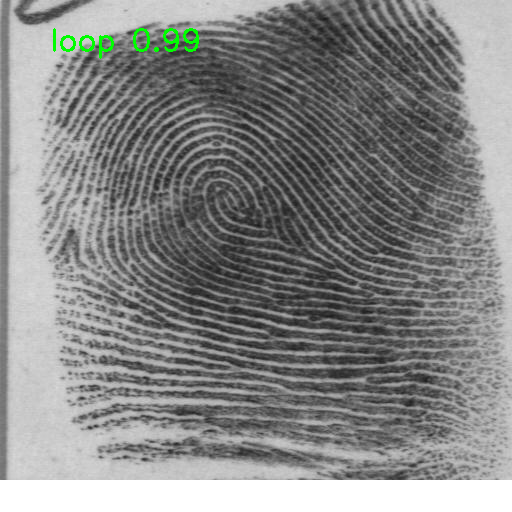

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

img=cv2.imread(filename=img_path)
cv2.putText(img,text=text,org=(50,50),fontFace=cv2.FONT_HERSHEY_SIMPLEX,fontScale=1,color=(0,255,0),thickness=2)
cv2_imshow(img)